<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/udlbook/Ch10_2_Convolutional_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [55]:
pip install mnist1d

In [56]:
import numpy as np
import os
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import matplotlib.pyplot as plt
import mnist1d
import random

Loads or regenerates the MNIST-1D dataset using the specified configuration and saves it at the given path.

In [57]:
args = mnist1d.data.get_dataset_args()
data = mnist1d.data.get_dataset(args, path='./mnist1d_data.pkl', download=False, regenerate=True)

Did or could not load data from ./mnist1d_data.pkl. Rebuilding dataset...


In [58]:
print("Examples in training set: {}".format(len(data['y'])))
print("Examples in test set: {}".format(len(data['y_test'])))
print("Length of each example: {}".format(data['x'].shape[-1]))

Examples in training set: 4000
Examples in test set: 1000
Length of each example: 40


Separates the dataset into training and test inputs (x) and their corresponding labels (y).

In [59]:
train_data_x = data['x']
train_data_y = data['y']

val_data_x = data['x_test']
val_data_y = data['y_test']

In [60]:
print("Train data: %d examples (columns), each of which has %d dimensions (rows)"%((train_data_x.shape[1],train_data_x.shape[0])))
print("Validation data: %d examples (columns), each of which has %d dimensions (rows)"%((val_data_x.shape[1],val_data_x.shape[0])))

Train data: 40 examples (columns), each of which has 4000 dimensions (rows)
Validation data: 40 examples (columns), each of which has 1000 dimensions (rows)


# Define the network

In [61]:
D_i = 40
D_o = 10

The model consists of three convolutional layers, each followed by a ReLU activation function.

- **First Convolutional Layer:** Takes a 1-channel input of length 40 and produces 15 output channels. It uses a kernel size of 3 and a stride of 2, reducing the output length to 19.
- **Second Convolutional Layer:** Takes 15 input channels and produces 15 output channels, reducing the length from 19 to 9.
- **Third Convolutional Layer:** Takes 15 input channels and produces 15 output channels, reducing the length from 9 to 4.
- **Flatten:** Converts the resulting feature maps (15 × 4) into a 60-dimensional vector.
- **Linear Layer:** Maps the 60-dimensional vector to 10 output values, corresponding to the 10 digit classes (0–9).

All convolutional layers use `valid` padding (no padding).

In [62]:
model = nn.Sequential(
    # First convolutional layer
    nn.Conv1d(in_channels=1, out_channels=15, kernel_size=3, stride=2),
    nn.ReLU(),

    # Second convolutional layer
    nn.Conv1d(in_channels=15, out_channels=15, kernel_size=3, stride=2),
    nn.ReLU(),

    # Third convolutional layer
    nn.Conv1d(in_channels=15, out_channels=15, kernel_size=3, stride=2),
    nn.ReLU(),

    # Flatten
    nn.Flatten(),

    # Fully connected layer
    nn.Linear(60, 10)
)

This function initializes the weights and biases of the neural network layers.

- `isinstance(layer_in, nn.Linear)`: Checks whether the input layer is a Linear layer.
- `nn.init.kaiming_uniform_(layer_in.weight)`: Initializes the weights using the Kaiming Uniform method, which is suitable for networks using ReLU activation functions.
- `layer_in.bias.data.fill_(0.0)`: Initializes all bias values to zero.

> The purpose of He Initialization is to maintain a stable variance of activations during training and help prevent vanishing or exploding gradients.

In [63]:
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

- **Loss Function** (`CrossEntropyLoss`): Measures the difference between the model's predicted outputs and the actual class labels. It is commonly used for multi-class classification tasks.

- **Optimizer** (`SGD`): Uses Stochastic Gradient Descent to update the model's weights and minimize the loss.
  - `lr=0.05`: Sets the initial learning rate to 0.05.
  - `momentum=0.9`: Helps accelerate convergence by using information from previous gradients.

- **Learning Rate Scheduler** (`StepLR`): Reduces the learning rate during training.
  - `step_size=20`: Updates the learning rate every 20 epochs.
  - `gamma=0.5`: Multiplies the learning rate by 0.5 at each step, reducing it by half.

> This setup helps the model learn effectively while gradually reducing the learning rate to improve convergence.

In [64]:
loss_funtion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr= 0.05, momentum= 0.9)
scheduler = StepLR(optimizer, step_size=20, gamma=0.5)

This code converts the training and validation datasets from NumPy arrays into PyTorch tensors.

- **Input data** (`x_train`, `x_val`): Converted to `float32` because neural network inputs and computations typically use floating-point values.
- **Target labels** (`y_train`, `y_val`): Converted to `long` (`int64`) because `CrossEntropyLoss` requires class labels to be integer indices.

> The training and validation data are now ready to be used with the PyTorch model.

In [65]:
x_train = torch.tensor(train_data_x.astype('float32'))
y_train = torch.tensor(train_data_y, dtype=torch.long)

x_val= torch.tensor(val_data_x.astype('float32'))
y_val = torch.tensor(val_data_y, dtype=torch.long)

The `DataLoader` prepares the training data for batch-based processing.

- `TensorDataset(x_train, y_train)`: Combines the input samples and their corresponding labels into a dataset.
- `batch_size=100`: Divides the dataset into batches of 100 samples.
- `shuffle=True`: Randomly shuffles the training data at the beginning of each epoch to prevent the model from learning the order of samples.
- `worker_init_fn`: Specifies a function to initialize each data-loading worker, allowing control over its random seed.

In [66]:
data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=100, shuffle=True, worker_init_fn=np.random.seed(1))

The `model.apply(weights_init)` method recursively applies the `weights_init` function to every layer and its submodules in the model.

It initializes the weights and biases of the specified layers using He (Kaiming) Initialization, helping prepare the network for training.

In [67]:
model.apply(weights_init)

Sequential(
  (0): Conv1d(1, 15, kernel_size=(3,), stride=(2,))
  (1): ReLU()
  (2): Conv1d(15, 15, kernel_size=(3,), stride=(2,))
  (3): ReLU()
  (4): Conv1d(15, 15, kernel_size=(3,), stride=(2,))
  (5): ReLU()
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=60, out_features=10, bias=True)
)

All arrays are initialized with zeros and will be updated during training to track the model's performance on both training and validation datasets.

In [68]:
epochs = 100

losses_train = np.zeros((epochs))
errors_train = np.zeros((epochs))
losses_val = np.zeros((epochs))
errors_val = np.zeros((epochs))

- **Training Loop:** Iterates through the training dataset in batches. Each batch is passed through the model, and its weights are updated using backpropagation and SGD.

- **Forward Pass:** Feeds each input batch into the CNN to generate predictions. `x_batch[:, None, :]` adds a channel dimension, changing the input shape from `(batch_size, 40)` to `(batch_size, 1, 40)`, as required by `Conv1d`.

- **Loss Calculation:** Uses `CrossEntropyLoss` to measure the difference between the model's predictions (logits) and the true labels.

- **Backward Pass:** Calculates the gradients of the loss with respect to the model parameters using `loss.backward()`.

- **Optimizer Step:** Uses `optimizer.step()` to update the model's weights and biases based on the calculated gradients.

- **Evaluation:** After each epoch, the model makes predictions on the entire training and validation datasets. It calculates the loss and classification error for both datasets to monitor model performance.

- **Metrics:** `torch.max()` extracts the predicted class with the highest output value. The classification error is calculated by comparing predicted classes with the true labels.

- **Learning Rate Scheduler:** Calls `scheduler.step()` at the end of each epoch to adjust the learning rate according to the predefined schedule.

In [69]:
for epoch in range(epochs):
  for i, data in enumerate(data_loader):
    x_pred, y_pred = data
    optimizer.zero_grad()
    pred = model(x_pred[:,None,:])
    loss = loss_funtion(pred, y_pred)
    loss.backward()
    optimizer.step()

  pred_train = model(x_train[:,None,:])
  pred_val = model(x_val[:,None,:])
  _, predicted_train_class = torch.max(pred_train.data, 1)
  _, predicted_val_class = torch.max(pred_val.data, 1)
  errors_train[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
  errors_val[epoch]= 100 - 100 * (predicted_val_class == y_val).float().sum() / len(y_val)
  losses_train[epoch] = loss_funtion(pred_train, y_train).item()
  losses_val[epoch]= loss_funtion(pred_val, y_val).item()

  if epoch % 10 == 0:
    print(f'Epoch {epoch:5d}, train loss {losses_train[epoch]:.6f}, train error {errors_train[epoch]:3.2f},  val loss {losses_val[epoch]:.6f}, percent error {errors_val[epoch]:3.2f}')

  scheduler.step()

Epoch     0, train loss 1.905677, train error 75.07,  val loss 1.928313, percent error 76.80
Epoch    10, train loss 0.649102, train error 25.60,  val loss 0.711478, percent error 29.30
Epoch    20, train loss 0.163088, train error 5.28,  val loss 0.293863, percent error 10.50
Epoch    30, train loss 0.098112, train error 3.00,  val loss 0.257722, percent error 8.30
Epoch    40, train loss 0.056691, train error 1.75,  val loss 0.256705, percent error 8.70
Epoch    50, train loss 0.037568, train error 0.65,  val loss 0.281723, percent error 8.70
Epoch    60, train loss 0.027333, train error 0.40,  val loss 0.289278, percent error 9.10
Epoch    70, train loss 0.023719, train error 0.28,  val loss 0.302161, percent error 8.60
Epoch    80, train loss 0.020559, train error 0.12,  val loss 0.308758, percent error 8.80
Epoch    90, train loss 0.019687, train error 0.15,  val loss 0.314411, percent error 8.60


Plots the training and validation error rates across epochs to visualize the model's performance and compare how well it learns from the training data and generalizes to unseen data. The final validation error is also displayed in the plot title.

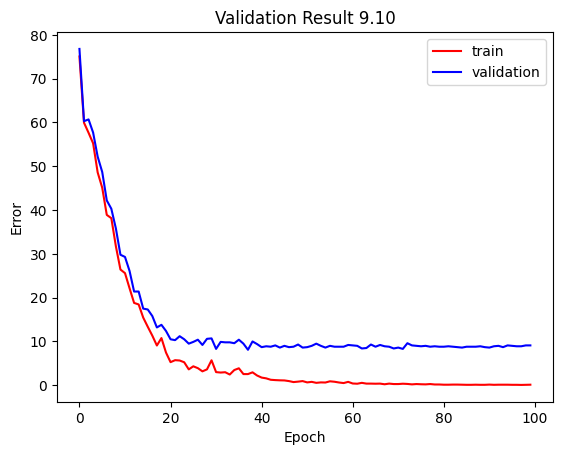

In [70]:
fig, ax = plt.subplots()
ax.plot(errors_train,'r-',label='train')
ax.plot(errors_val,'b-',label='validation')
ax.set_xlabel('Epoch')
ax.set_ylabel('Error')
ax.set_title('Validation Result %3.2f'%(errors_val[-1]))
ax.legend()
plt.show()

**Results Analysis**

The model learns effectively during the first 30 epochs, with both training and validation errors decreasing significantly. After that, the training loss continues to decrease, while the validation loss starts increasing, indicating overfitting. The best validation error is 8.30%, achieved at epoch 30.